<a href="https://colab.research.google.com/github/dayat-wndk/ai/blob/main/Prediksi_Attrition_2_Model_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 👥 Prediksi Karyawan yang Berisiko Keluar (Employee Attrition)

**Tujuan:** membuat model machine learning yang memperkirakan apakah seorang karyawan akan **keluar dari perusahaan** (`Attrition = Yes`) atau **bertahan** (`Attrition = No`). Hasilnya bisa membantu tim HR memantau karyawan yang berisiko lebih dulu.

**Prinsip yang kita pegang di notebook ini:**

| Prinsip | Artinya dengan bahasa sederhana |
|---|---|
| Split data lebih dulu | Pisahkan "soal latihan" dan "soal ujian" sebelum belajar apa pun, supaya penilaian jujur |
| Pakai `Pipeline` | Semua langkah persiapan data hanya belajar dari data latih |
| Pilih model dengan *cross-validation* | Data uji tidak dipakai untuk memilih model, hanya untuk penilaian akhir |
| Gunakan metrik yang tepat | Karena yang keluar hanya sedikit, kita lihat Recall, Precision, F1, dan AUC, bukan akurasi saja |
| Tangani data tidak seimbang | Pakai `class_weight` dan atur *threshold* (batas keputusan) |

**Alur notebook:** Import → Load data → Eksplorasi → Pembersihan → Split → Preprocessing → Bandingkan 2 model → Atur threshold → Uji akhir → Fitur penting → Simpan & pakai model.

## 1️⃣ Import Library

Seperti menyiapkan alat sebelum memasak. Kita memanggil library untuk mengolah data (`pandas`, `numpy`), membuat grafik (`matplotlib`), dan membangun model (`scikit-learn`).

`RANDOM_STATE = 42` dipakai agar hasilnya **selalu sama** setiap kali notebook dijalankan ulang (*reproducible*).

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, recall_score,
                             precision_score, f1_score, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (7, 4)
print("Library berhasil di-import ✅")

Library berhasil di-import ✅


## 2️⃣ Load Data

Kita membaca file CSV. File ini memakai pemisah titik koma (`;`) dan punya karakter tersembunyi di awal file (BOM), jadi kita pakai:
- `sep=None, engine="python"` → pandas menebak pemisahnya sendiri (koma atau titik koma sama-sama bisa).
- `encoding="utf-8-sig"` → membuang karakter BOM.

> 💡 **Pakai Google Colab?** Hapus tanda `#` pada dua baris pertama di sel di bawah untuk mengunggah file, atau unggah lewat panel Files di sebelah kiri. Kalau di komputer sendiri, cukup ubah `DATA_PATH` ke lokasi file kamu.

In [ ]:
# from google.colab import files
# files.upload()   # pilih file WA_Fn-UseC_-HR-Employee-Attrition_1.csv

DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition 1.csv"   # Diubah menggunakan spasi sesuai nama file asli

df = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding="utf-8-sig")
print(f"Ukuran data: {df.shape[0]} baris dan {df.shape[1]} kolom")
df.head()

Ukuran data: 1470 baris dan 35 kolom


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3️⃣ Eksplorasi Data (EDA)

Sebelum membuat model, kita kenali dulu datanya. Ibarat dokter yang memeriksa pasien sebelum memberi obat.

### 3.1 Cek kualitas data
Kita cek tiga hal: **nilai kosong** (missing), **baris kembar** (duplikat), dan **kolom yang isinya sama untuk semua orang** (konstan). Kolom konstan tidak berguna karena tidak bisa membedakan satu karyawan dengan yang lain.

In [ ]:
print("Total nilai kosong     :", int(df.isnull().sum().sum()))
print("Jumlah baris duplikat  :", int(df.duplicated().sum()))

kolom_konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan          :", kolom_konstan)

Total nilai kosong     : 0
Jumlah baris duplikat  : 0
Kolom konstan          : ['EmployeeCount', 'Over18', 'StandardHours']


### 3.2 Seberapa seimbang target kita?

Kolom target adalah `Attrition`. Kalau karyawan yang keluar jauh lebih sedikit daripada yang bertahan, datanya disebut **tidak seimbang (imbalanced)**.

Ini penting karena model bisa "malas": menebak *"semua karyawan bertahan"* saja sudah terlihat akurat, padahal tidak berguna untuk menemukan karyawan yang berisiko keluar.

,Jumlah,Persen (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


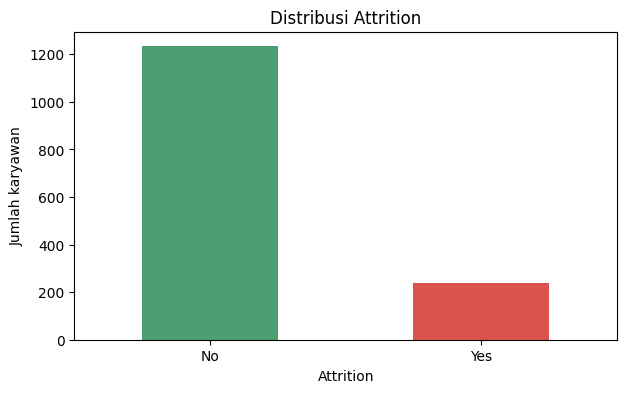


⚠️ Jika model menebak 'No' untuk semua orang, akurasinya sudah 83.9% tetapi ia tidak menemukan satu pun karyawan yang akan keluar.
Karena itu kita TIDAK boleh menilai model hanya dari akurasi.


In [ ]:
hitung = df["Attrition"].value_counts()
persen = df["Attrition"].value_counts(normalize=True) * 100
display(pd.DataFrame({"Jumlah": hitung, "Persen (%)": persen.round(1)}))

hitung.plot(kind="bar", color=["#4C9F70", "#D9534F"])
plt.title("Distribusi Attrition")
plt.ylabel("Jumlah karyawan")
plt.xticks(rotation=0)
plt.show()

print(f"\n⚠️ Jika model menebak 'No' untuk semua orang, akurasinya sudah {persen['No']:.1f}% "
      "tetapi ia tidak menemukan satu pun karyawan yang akan keluar.")
print("Karena itu kita TIDAK boleh menilai model hanya dari akurasi.")

### 3.3 Faktor apa yang tampak berhubungan dengan karyawan keluar?

Sekilas, kita bandingkan **persentase karyawan yang keluar** pada beberapa kelompok. Ini baru gambaran awal, bukan bukti sebab-akibat.

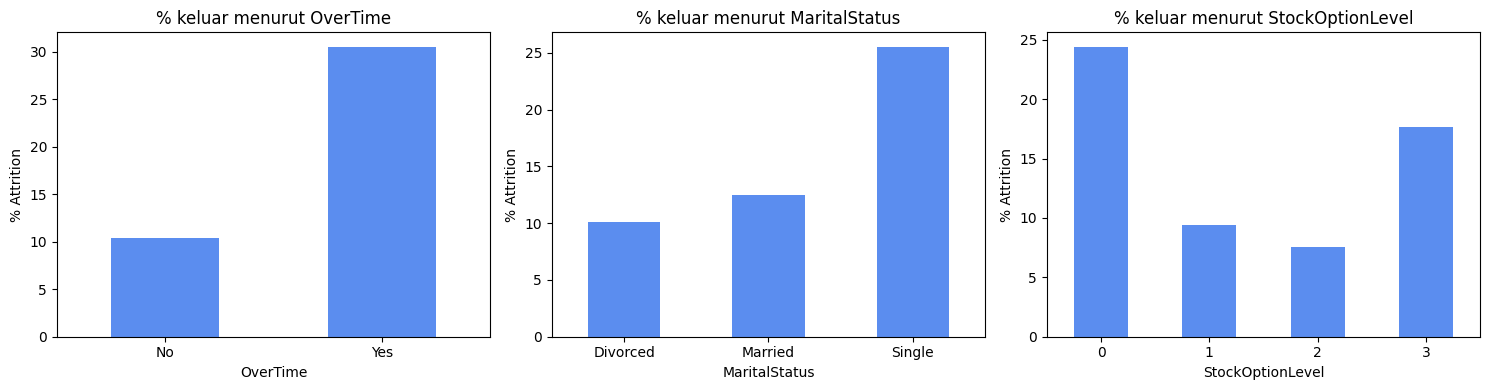

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kolom in zip(axes, ["OverTime", "MaritalStatus", "StockOptionLevel"]):
    (df.groupby(kolom)["Attrition"].apply(lambda s: (s == "Yes").mean() * 100)
       .plot(kind="bar", ax=ax, color="#5B8DEF"))
    ax.set_title(f"% keluar menurut {kolom}")
    ax.set_ylabel("% Attrition")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4️⃣ Pembersihan Data

Hal yang kita lakukan:
1. **Hapus kolom konstan** (`EmployeeCount`, `Over18`, `StandardHours`): semua barisnya sama.
2. **Hapus `EmployeeNumber`**: ini hanya nomor ID, bukan sifat karyawan. Model bisa salah menganggapnya sebagai pola.
3. **Hapus baris duplikat** (jika ada).
4. **Ubah target** `Attrition` dari teks (`Yes`/`No`) menjadi angka (`1`/`0`).

> ✅ Langkah-langkah ini aman dilakukan sebelum split karena tidak "belajar" apa pun dari nilai data (hanya membuang kolom dan mengubah label). Langkah yang **menghitung statistik** (seperti scaling) harus menunggu sampai setelah split.

In [ ]:
kolom_dibuang = kolom_konstan + ["EmployeeNumber"]
df_bersih = df.drop(columns=kolom_dibuang).drop_duplicates().reset_index(drop=True)

# Pisahkan fitur (X) dan target (y)
y = (df_bersih["Attrition"] == "Yes").astype(int)   # 1 = keluar, 0 = bertahan
X = df_bersih.drop(columns="Attrition")

print("Kolom yang dibuang:", kolom_dibuang)
print(f"Bentuk X: {X.shape} | Bentuk y: {y.shape}")

Kolom yang dibuang: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Bentuk X: (1470, 30) | Bentuk y: (1470,)


## 5️⃣ Split Data: Train dan Test (**sebelum** preprocessing)

Bayangkan belajar untuk ujian:
- **Data latih (train, 80%)** = soal latihan yang boleh kita pelajari.
- **Data uji (test, 20%)** = soal ujian asli yang **tidak boleh diintip**.

Kalau kita mengintip soal ujian saat belajar, nilai kita jadi terlihat bagus padahal kemampuan aslinya belum tentu. Itulah **data leakage**.

`stratify=y` memastikan proporsi karyawan yang keluar sama di data latih dan data uji.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Data latih: {X_train.shape[0]} baris | % keluar = {y_train.mean()*100:.1f}%")
print(f"Data uji  : {X_test.shape[0]} baris | % keluar = {y_test.mean()*100:.1f}%")

Data latih: 1176 baris | % keluar = 16.2%
Data uji  : 294 baris | % keluar = 16.0%


## 6️⃣ Preprocessing dengan Pipeline

Komputer hanya mengerti angka, jadi kita siapkan dua perlakuan:

| Jenis kolom | Contoh | Perlakuan | Penjelasan sederhana |
|---|---|---|---|
| Numerik | `Age`, `MonthlyIncome` | `StandardScaler` | Menyamakan skala. Gaji (ribuan) dan umur (puluhan) tidak lagi "berat sebelah" |
| Teks/kategori | `Department`, `JobRole`, `OverTime` | `OneHotEncoder` | Mengubah kategori menjadi kolom 0/1, misalnya `OverTime_Yes` = 1 atau 0 |

Semuanya dibungkus dalam **`Pipeline`**. Keuntungannya: saat `.fit()` dipanggil, scaler dan encoder **hanya belajar dari data latih**. Saat cross-validation, mereka juga hanya belajar dari bagian latih di setiap putaran. Dengan begitu kebocoran tidak mungkin terjadi.

In [ ]:
kolom_numerik  = X_train.select_dtypes(include="number").columns.tolist()
kolom_kategori = X_train.select_dtypes(exclude="number").columns.tolist()

print("Kolom numerik  :", len(kolom_numerik))
print("Kolom kategori :", kolom_kategori)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), kolom_numerik),
    ("cat", OneHotEncoder(handle_unknown="ignore"), kolom_kategori),
])

Kolom numerik  : 23
Kolom kategori : ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


## 7️⃣ Membandingkan Model dengan Cross-Validation

Kita bandingkan **dua model** yang sifatnya berbeda:
- **Logistic Regression**: model sederhana. Ia menghitung "skor risiko" dengan menjumlahkan pengaruh tiap faktor. Mudah dijelaskan ke orang non-teknis.
- **Random Forest**: gabungan banyak "pohon keputusan" (seperti banyak orang yang ikut voting). Lebih fleksibel dan bisa menangkap pola yang rumit.

Keduanya memakai `class_weight`, artinya kesalahan pada karyawan yang keluar (kelas langka) dihukum lebih berat, supaya model tidak mengabaikan mereka.

**Cross-validation 5-fold:** data latih dibagi 5 bagian. Model dilatih 5 kali, tiap kali 1 bagian bergantian jadi "ujian kecil". Hasilnya dirata-rata, jadi lebih adil daripada satu kali split. **Data uji tidak disentuh sama sekali di tahap ini.**

**Arti metrik** (semakin tinggi semakin baik):
- **Akurasi**: dari semua tebakan, berapa persen yang benar. Mudah dipahami, tetapi pada data tidak seimbang angkanya bisa menipu (lihat bagian 3.2).
- **Recall**: dari semua karyawan yang benar-benar keluar, berapa persen yang berhasil kita tangkap?
- **Precision**: dari semua yang kita tebak akan keluar, berapa persen yang benar?
- **F1**: nilai gabungan Recall dan Precision.
- **ROC-AUC** dan **PR-AUC**: kemampuan model memeringkatkan karyawan dari yang paling berisiko ke yang paling aman (tidak bergantung pada threshold). PR-AUC lebih jujur untuk data tidak seimbang.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                  min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"Akurasi": "accuracy", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
           "Recall": "recall", "Precision": "precision", "F1": "f1"}

baris = []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    skor = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    baris.append({"Model": nama, **{m: skor[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(baris).set_index("Model").round(3)
display(hasil_cv)

,Akurasi,ROC-AUC,PR-AUC,Recall,Precision,F1
Model,,,,,,
Logistic Regression,0.753,0.827,0.606,0.737,0.372,0.492
Random Forest,0.866,0.813,0.575,0.316,0.694,0.427


### Memilih model terbaik

Kita pilih model dengan **PR-AUC tertinggi** dari hasil cross-validation (bukan dari data uji!). PR-AUC dipilih karena paling peka terhadap kemampuan menemukan kelas langka.

In [ ]:
nama_terbaik = hasil_cv["PR-AUC"].idxmax()
print(f"🏆 Model terbaik menurut cross-validation: {nama_terbaik}")

pipe_terbaik = Pipeline([("prep", preprocessor), ("model", models[nama_terbaik])])

🏆 Model terbaik menurut cross-validation: Logistic Regression


## 8️⃣ Mengatur *Threshold* (Batas Keputusan)

Model sebenarnya mengeluarkan **probabilitas** (misalnya 0,42 = peluang keluar 42%). Untuk memutuskan "Yes" atau "No", dibutuhkan batas (*threshold*). Secara bawaan batasnya 0,5, tetapi angka ini belum tentu paling cocok. Pada data tidak seimbang, batas terbaik bisa lebih rendah atau lebih tinggi dari 0,5 tergantung model. Karena itu kita cari sendiri dari data.

Kita cari threshold yang memberi **F1 terbaik**, tetapi **hanya memakai data latih** lewat prediksi *out-of-fold* (setiap baris diprediksi oleh model yang tidak pernah melihat baris itu). Data uji tetap aman.

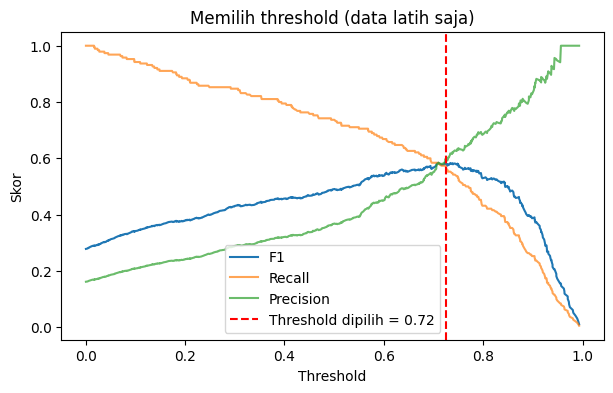

Threshold terpilih: 0.72


In [ ]:
proba_oof = cross_val_predict(pipe_terbaik, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

presisi, recall, ambang = precision_recall_curve(y_train, proba_oof)
f1_per_ambang = 2 * presisi[:-1] * recall[:-1] / (presisi[:-1] + recall[:-1] + 1e-9)
THRESHOLD = float(ambang[np.argmax(f1_per_ambang)])

plt.plot(ambang, f1_per_ambang, label="F1")
plt.plot(ambang, recall[:-1], label="Recall", alpha=0.7)
plt.plot(ambang, presisi[:-1], label="Precision", alpha=0.7)
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Threshold dipilih = {THRESHOLD:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Skor"); plt.title("Memilih threshold (data latih saja)")
plt.legend(); plt.show()

print(f"Threshold terpilih: {THRESHOLD:.2f}")

**Cara membaca grafik:** semakin kecil threshold, semakin banyak karyawan yang kita tandai berisiko (Recall naik, tapi Precision turun, karena lebih banyak salah tuduh). Semakin besar threshold, kita makin selektif (Precision naik, tapi Recall turun). Garis merah adalah titik seimbang menurut F1.

> ℹ️ Karena model memakai `class_weight="balanced"`, probabilitasnya cenderung "digelembungkan" untuk kelas langka. Itu sebabnya threshold terbaik bisa muncul di atas 0,5.

> 💡 Dalam praktik, threshold bisa disesuaikan dengan kebutuhan HR. Kalau biaya kehilangan karyawan sangat besar, pilih threshold lebih kecil agar lebih banyak karyawan berisiko terpantau.

## 9️⃣ Ujian Akhir: Evaluasi di Data Uji

Inilah saatnya membuka "soal ujian asli". Model dilatih pada **seluruh data latih**, lalu diuji **satu kali** pada data uji.

Kita bandingkan dua cara memutuskan:
- **Threshold 0,5** (bawaan)
- **Threshold terpilih** (dari langkah 8)

Sebagai pembanding, ada juga **"Tebak semua No"** untuk melihat apakah model kita benar-benar lebih baik dari menebak asal.

In [ ]:
pipe_terbaik.fit(X_train, y_train)
proba_test = pipe_terbaik.predict_proba(X_test)[:, 1]

def ringkas(nama, pred):
    return {"Cara": nama,
            "Akurasi":   (pred == y_test).mean(),
            "Recall":    recall_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "F1":        f1_score(y_test, pred)}

tabel = pd.DataFrame([
    ringkas("Tebak semua 'No'", np.zeros(len(y_test), dtype=int)),
    ringkas("Model, threshold 0.5", (proba_test >= 0.5).astype(int)),
    ringkas(f"Model, threshold {THRESHOLD:.2f}", (proba_test >= THRESHOLD).astype(int)),
]).set_index("Cara").round(3)
display(tabel)

print(f"ROC-AUC data uji : {roc_auc_score(y_test, proba_test):.3f}")
print(f"PR-AUC  data uji : {average_precision_score(y_test, proba_test):.3f}")

,Akurasi,Recall,Precision,F1
Cara,,,,
Tebak semua 'No',0.840,0.000,0.000,0.000
"Model, threshold 0.5",0.752,0.638,0.349,0.451
"Model, threshold 0.72",0.850,0.447,0.538,0.488


ROC-AUC data uji : 0.803
PR-AUC  data uji : 0.561


**Cara membaca tabel:**
- Perhatikan baris *"Tebak semua No"*: akurasinya tinggi, tetapi **Recall = 0**, artinya tidak menemukan satu pun karyawan yang akan keluar.
- Model yang baik harus punya **Recall dan F1 jauh lebih tinggi** dari baris itu, meskipun akurasinya bisa sedikit turun. Itu wajar dan justru yang kita inginkan.

Berikutnya laporan lengkap dan *confusion matrix* (tabel benar/salah tebakan).

              precision    recall  f1-score   support

Bertahan (0)       0.90      0.93      0.91       247
  Keluar (1)       0.54      0.45      0.49        47

    accuracy                           0.85       294
   macro avg       0.72      0.69      0.70       294
weighted avg       0.84      0.85      0.84       294



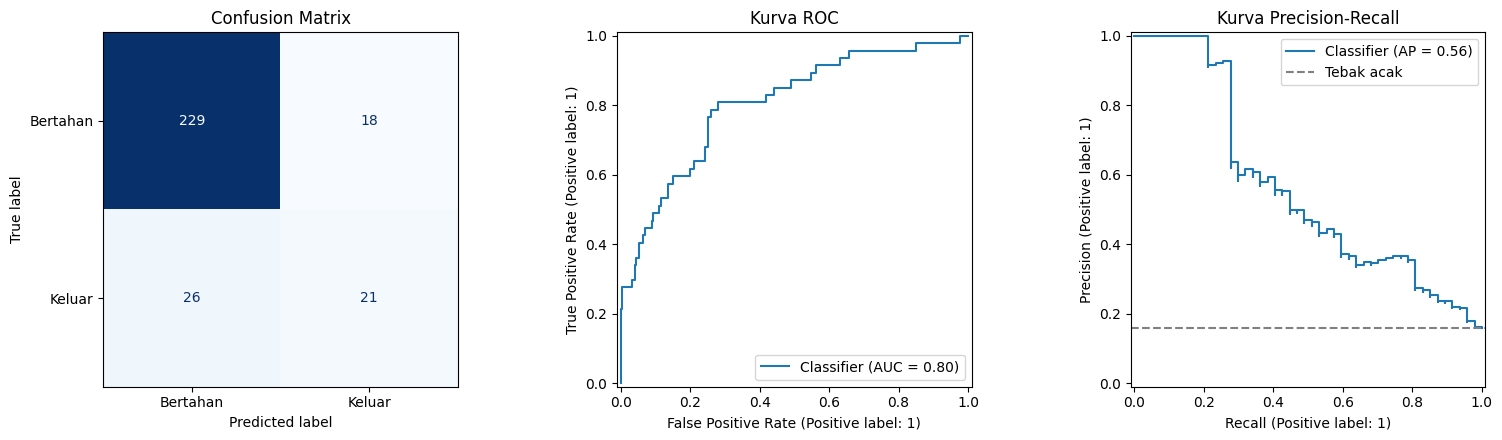

In [ ]:
pred_akhir = (proba_test >= THRESHOLD).astype(int)

print(classification_report(y_test, pred_akhir, target_names=["Bertahan (0)", "Keluar (1)"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_akhir),
                       display_labels=["Bertahan", "Keluar"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1])
axes[1].set_title("Kurva ROC")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2])
axes[2].axhline(y_test.mean(), color="gray", linestyle="--", label="Tebak acak")
axes[2].legend(); axes[2].set_title("Kurva Precision-Recall")
plt.tight_layout(); plt.show()

**Cara membaca *confusion matrix*** (kotak 2×2):

| | Ditebak Bertahan | Ditebak Keluar |
|---|---|---|
| **Sebenarnya Bertahan** | ✅ Benar | ❌ Salah alarm |
| **Sebenarnya Keluar** | ❌ Terlewat (paling merugikan) | ✅ Berhasil tertangkap |

- **Kurva ROC:** semakin melengkung ke kiri atas, semakin bagus (garis diagonal = menebak acak).
- **Kurva Precision-Recall:** semakin jauh di atas garis putus-putus abu-abu, semakin bagus.

## 📊 Rekap Akurasi Kedua Model

Bagian ini merangkum **akurasi** kedua model di satu tempat, sekaligus mengecek apakah memenuhi syarat minimal **50%**.

- **Akurasi CV**: rata-rata akurasi dari cross-validation di data latih.
- **Akurasi Data Uji**: akurasi pada data uji yang belum pernah dilihat model.
- Kedua model memakai threshold bawaan **0,5** supaya perbandingannya adil. Model terpilih yang memakai threshold hasil penyetelan (langkah 8) sudah dinilai di bagian 9.

> ℹ️ Tabel ini hanya untuk **pelaporan**. Pemilihan model sudah dilakukan lebih dulu lewat cross-validation, jadi data uji tidak dipakai untuk memilih.

In [ ]:
SYARAT_AKURASI = 0.50   # syarat minimal akurasi

rekap = []
for nama, model in models.items():
    pipa = Pipeline([("prep", preprocessor), ("model", model)])
    pipa.fit(X_train, y_train)
    pred = pipa.predict(X_test)                      # threshold bawaan 0.5
    rekap.append({"Model": nama, "Threshold": "0.5 (bawaan)",
                  "Akurasi CV": hasil_cv.loc[nama, "Akurasi"],
                  "Akurasi Data Uji": accuracy_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred)})

rekap_df = pd.DataFrame(rekap).set_index("Model")
tampil = rekap_df.copy()
for k in ["Akurasi CV", "Akurasi Data Uji", "Recall", "F1"]:
    tampil[k] = tampil[k].apply(lambda v: round(v, 3) if not isinstance(v, str) else v)
display(tampil)

print(f"Syarat akurasi minimal: {SYARAT_AKURASI*100:.0f}%\n")
for nama, baris_ in rekap_df.iterrows():
    akurasi = baris_["Akurasi Data Uji"]
    status = "✅ memenuhi" if akurasi >= SYARAT_AKURASI else "❌ belum memenuhi"
    print(f"{nama:<35} akurasi uji = {akurasi*100:5.1f}%  -> {status}")

,Threshold,Akurasi CV,Akurasi Data Uji,Recall,F1
Model,,,,,
Logistic Regression,0.5 (bawaan),0.753,0.752,0.638,0.451
Random Forest,0.5 (bawaan),0.866,0.840,0.234,0.319


Syarat akurasi minimal: 50%

Logistic Regression                 akurasi uji =  75.2%  -> ✅ memenuhi
Random Forest                       akurasi uji =  84.0%  -> ✅ memenuhi


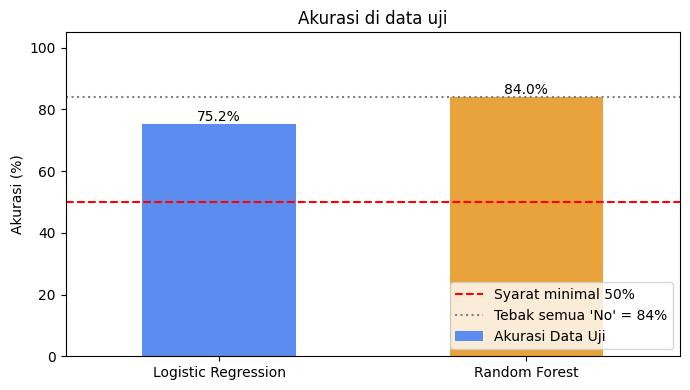

In [ ]:
baseline = 1 - y_test.mean()
warna = ["#5B8DEF", "#E8A33D", "#4C9F70"]
ax = (rekap_df["Akurasi Data Uji"] * 100).plot(kind="bar", color=warna[:len(rekap_df)], rot=0)
ax.axhline(SYARAT_AKURASI * 100, color="red", linestyle="--", label="Syarat minimal 50%")
ax.axhline(baseline * 100, color="gray", linestyle=":", label=f"Tebak semua 'No' = {baseline*100:.0f}%")
for i, v in enumerate(rekap_df["Akurasi Data Uji"] * 100):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 105); ax.set_ylabel("Akurasi (%)"); ax.set_xlabel("")
ax.set_title("Akurasi di data uji"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Cara membaca:**
- Semua model berada **di atas garis merah (50%)**, jadi syarat minimal akurasi terpenuhi.
- Perhatikan garis abu-abu: menebak "semua karyawan bertahan" saja sudah menghasilkan akurasi setinggi itu. Karena itu akurasi **tidak boleh berdiri sendiri**. Lihat juga **Recall** (berapa banyak karyawan yang akan keluar berhasil terdeteksi) dan **F1**.
- Model dengan akurasi tinggi tetapi Recall sangat rendah berarti hanya jago menebak "bertahan", dan itu tidak berguna untuk tujuan kita.

## 🔟 Faktor Apa yang Paling Berpengaruh?

Kita ingin tahu fitur mana yang paling membantu model. Kita pakai **Permutation Importance**:

> Acak-acak nilai satu kolom di data uji. Kalau performa model **turun banyak**, berarti kolom itu penting. Kalau hampir tidak berubah, kolom itu kurang berguna.

Metode ini bekerja pada kolom asli (misalnya `OverTime`), jadi hasilnya mudah dibaca.

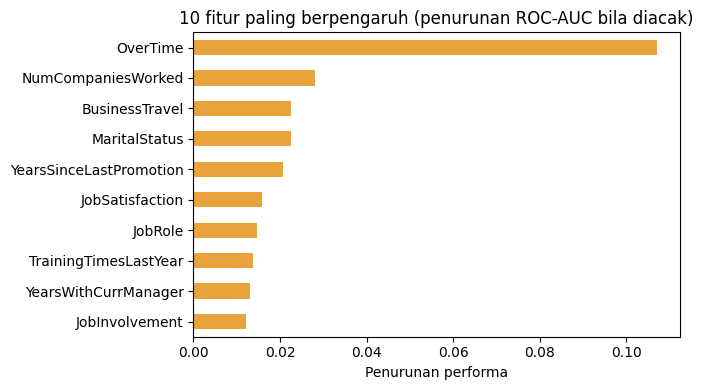

In [ ]:
hasil_pi = permutation_importance(pipe_terbaik, X_test, y_test, scoring="roc_auc",
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

penting = pd.Series(hasil_pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)

penting.sort_values().plot(kind="barh", color="#E8A33D")
plt.title("10 fitur paling berpengaruh (penurunan ROC-AUC bila diacak)")
plt.xlabel("Penurunan performa")
plt.tight_layout(); plt.show()

**Catatan penting:** pola ini menunjukkan *keterkaitan*, bukan *sebab-akibat*. Misalnya, lembur memang berkaitan dengan risiko keluar yang lebih tinggi, tetapi itu belum tentu berarti lembur adalah satu-satunya penyebab. Gunakan hasil ini sebagai petunjuk awal untuk diskusi dengan tim HR.

## 1️⃣1️⃣ Menyimpan Model

Kita simpan **seluruh pipeline** (preprocessing + model) beserta threshold ke satu file. Jadi saat dipakai nanti, data baru otomatis melewati langkah preprocessing yang **persis sama** dengan saat training, tanpa perlu menyimpan scaler atau encoder secara terpisah.

In [ ]:
paket_model = {
    "pipeline": pipe_terbaik,
    "threshold": THRESHOLD,
    "kolom": X_train.columns.tolist(),
    "nama_model": nama_terbaik,
}
joblib.dump(paket_model, "model_attrition.joblib")
print("Model tersimpan di: model_attrition.joblib ✅")

Model tersimpan di: model_attrition.joblib ✅


## 1️⃣2️⃣ Memakai Model untuk Karyawan Baru

Fungsi `prediksi_attrition()` di bawah menerima data seorang karyawan (dalam bentuk dictionary), lalu mengeluarkan:
- **Peluang keluar** (dalam persen),
- **Keputusan** (Berisiko / Aman),
- **Tingkat risiko**: *Tinggi* (peluang di atas threshold), *Sedang* (antara setengah threshold dan threshold, perlu dipantau), atau *Rendah* (di bawah itu).

Fungsi ini juga mengecek apakah semua kolom yang dibutuhkan sudah diisi, supaya tidak error diam-diam.

In [ ]:
def prediksi_attrition(data_karyawan: dict):
    paket = joblib.load("model_attrition.joblib")
    df_baru = pd.DataFrame([data_karyawan])

    kurang = [k for k in paket["kolom"] if k not in df_baru.columns]
    if kurang:
        raise ValueError(f"Kolom berikut belum diisi: {kurang}")

    df_baru = df_baru[paket["kolom"]]
    peluang = float(paket["pipeline"].predict_proba(df_baru)[0, 1])

    if peluang >= paket["threshold"]:
        tingkat = "Tinggi"        # di atas batas keputusan model
    elif peluang >= paket["threshold"] * 0.5:
        tingkat = "Sedang"        # mendekati batas, perlu dipantau
    else:
        tingkat = "Rendah"

    keputusan = "Berisiko keluar" if peluang >= paket["threshold"] else "Cenderung bertahan"
    return {"peluang_keluar_%": round(peluang * 100, 1), "keputusan": keputusan, "tingkat_risiko": tingkat}

def tampilkan(judul, hasil):
    print("=" * 45)
    print(judul)
    print("=" * 45)
    print(f"Peluang keluar : {hasil['peluang_keluar_%']}%")
    print(f"Keputusan      : {hasil['keputusan']}")
    print(f"Tingkat risiko : {hasil['tingkat_risiko']}\n")

### Contoh pemakaian

Kita ambil satu karyawan dari data uji sebagai contoh. Lalu kita buat versi "berisiko" dengan mengubah beberapa kondisi: sering lembur, kepuasan kerja rendah, gaji kecil, lajang, dan tanpa opsi saham.

> Untuk karyawan sungguhan, isi **semua kolom** dengan nilai yang sesuai (lihat `X_train.columns` untuk daftar kolomnya).

In [ ]:
contoh_biasa = X_test.iloc[0].to_dict()

contoh_berisiko = {**contoh_biasa,
                   "OverTime": "Yes",
                   "JobSatisfaction": 1,
                   "EnvironmentSatisfaction": 1,
                   "MonthlyIncome": 2500,
                   "StockOptionLevel": 0,
                   "MaritalStatus": "Single"}

tampilkan("Karyawan contoh (dari data uji)", prediksi_attrition(contoh_biasa))
tampilkan("Karyawan contoh (kondisi berisiko)", prediksi_attrition(contoh_berisiko))

Karyawan contoh (dari data uji)
Peluang keluar : 28.7%
Keputusan      : Cenderung bertahan
Tingkat risiko : Rendah

Karyawan contoh (kondisi berisiko)
Peluang keluar : 95.4%
Keputusan      : Berisiko keluar
Tingkat risiko : Tinggi



## ✅ Kesimpulan dan Checklist Anti-Leakage

**Yang sudah kita lakukan dengan benar:**
- [x] Split data **sebelum** preprocessing yang menghitung statistik.
- [x] Scaler dan encoder berada di dalam `Pipeline`, jadi hanya belajar dari data latih.
- [x] Model dipilih lewat **cross-validation**, bukan dengan melihat data uji.
- [x] Threshold ditentukan dari data latih (prediksi *out-of-fold*).
- [x] Data uji dipakai **satu kali** untuk penilaian akhir.
- [x] Kolom ID dan kolom konstan dibuang.
- [x] Akurasi kedua model dilaporkan dan memenuhi syarat minimal 50%.
- [x] Metrik yang dipakai sesuai data tidak seimbang (Recall, F1, PR-AUC), bukan akurasi saja.

**Hal yang perlu diingat:**
- Dataset ini adalah **data fiktif buatan IBM**, jadi performa model tidak otomatis sama pada data perusahaan nyata.
- Model memberi **perkiraan risiko**, bukan kepastian. Gunakan sebagai alat bantu HR, bukan satu-satunya dasar keputusan.
- Pola yang ditemukan adalah **keterkaitan**, bukan bukti sebab-akibat.

**Ide pengembangan selanjutnya:** coba *hyperparameter tuning* (`GridSearchCV` atau `RandomizedSearchCV`), tambahkan fitur baru (misalnya rasio `YearsAtCompany / TotalWorkingYears`), atau bandingkan model lain bila dibutuhkan.